# EDA & Visualisasi Data Asli Yaboo Kopi (139 Hari Operasional)
**PIC Data Science 3 (`@elen`) | Tim Capstone A26-CS216**

In [1]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath(".."))
from app.services.analytics_aggregator import YabooAnalyticsAggregator

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
os.makedirs("eda_charts_real", exist_ok=True)

agg = YabooAnalyticsAggregator()
top_menus = pd.DataFrame(agg.get_top_menus(top_n=10))
pay_methods = pd.DataFrame(agg.get_payment_methods())
trend_payload = agg.get_daily_revenue_profit_trend()
df_trend = pd.DataFrame(trend_payload["daily_series"])
df_trend["tanggal"] = pd.to_datetime(df_trend["tanggal"])

print("Ringkasan Utama:", trend_payload["summary"])

Ringkasan Utama: {'total_hari': 139, 'periode': '2026-07-07 s/d 2026-11-22', 'total_omset_idr': 85536000, 'total_laba_bersih_idr': 57759528, 'rata_rata_omset_harian_idr': 615366.91, 'rata_rata_laba_harian_idr': 415536.17, 'total_cup_terjual': 5948}


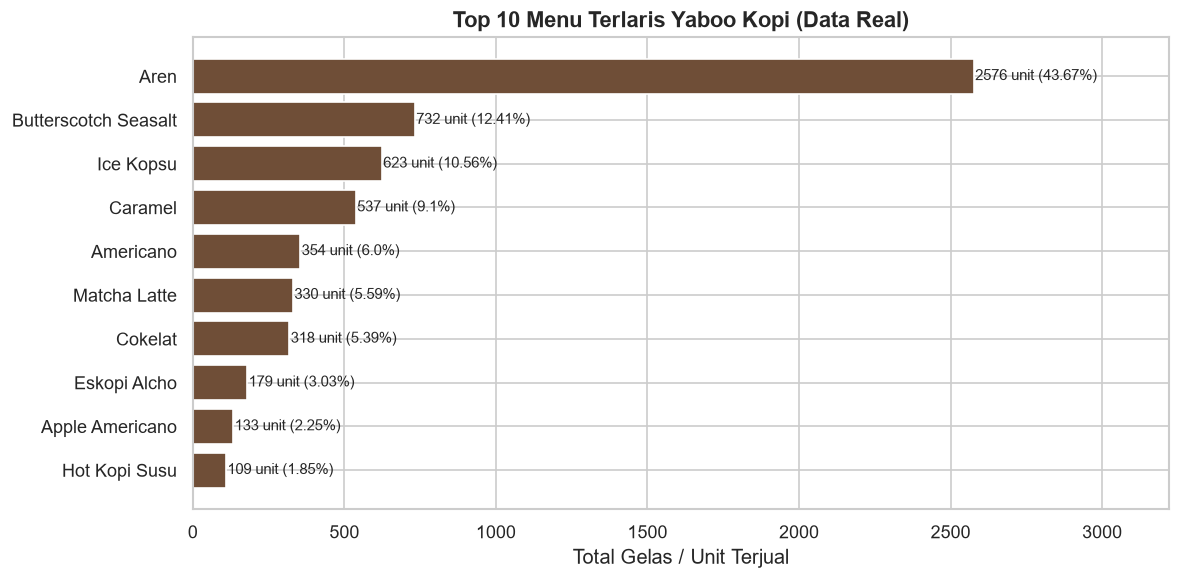

In [2]:
plot_menu = top_menus.sort_values("total_cup", ascending=True)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(plot_menu["nama_produk"], plot_menu["total_cup"], color="#6F4E37")
ax.set_title("Top 10 Menu Terlaris Yaboo Kopi (Data Real)", fontsize=13, fontweight="bold")
ax.set_xlabel("Total Gelas / Unit Terjual")
for bar, pct in zip(bars, plot_menu["kontribusi_cup_pct"]):
    ax.text(
        bar.get_width() + 5,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width())} unit ({pct}%)",
        va="center",
        fontsize=9,
    )
ax.set_xlim(0, plot_menu["total_cup"].max() * 1.25)
plt.tight_layout()
plt.savefig("eda_charts_real/01_top_menu_real_yaboo.png")
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_7136\3486239218.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pay_methods, x="metode_bayar", y="jumlah_transaksi", ax=axes[0], palette="Set2")


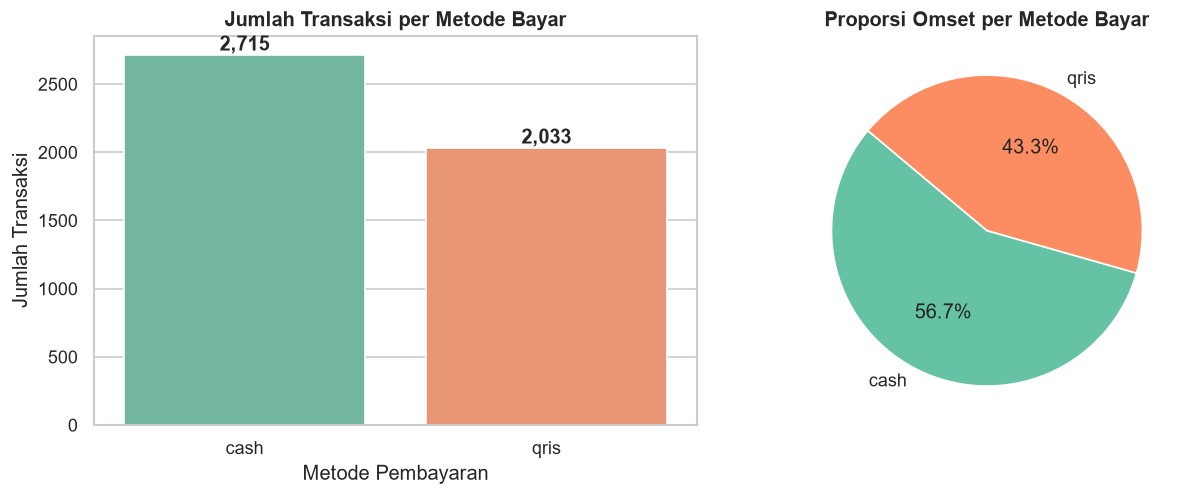

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
sns.barplot(data=pay_methods, x="metode_bayar", y="jumlah_transaksi", ax=axes[0], palette="Set2")
axes[0].set_title("Jumlah Transaksi per Metode Bayar", fontweight="bold")
axes[0].set_xlabel("Metode Pembayaran")
axes[0].set_ylabel("Jumlah Transaksi")
for p in axes[0].patches:
    axes[0].annotate(
        f"{int(p.get_height()):,}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontweight="bold",
    )

axes[1].pie(
    pay_methods["total_nominal_idr"],
    labels=pay_methods["metode_bayar"],
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("Set2"),
)
axes[1].set_title("Proporsi Omset per Metode Bayar", fontweight="bold")
plt.tight_layout()
plt.savefig("eda_charts_real/02_metode_bayar_real_yaboo.png")
plt.show()

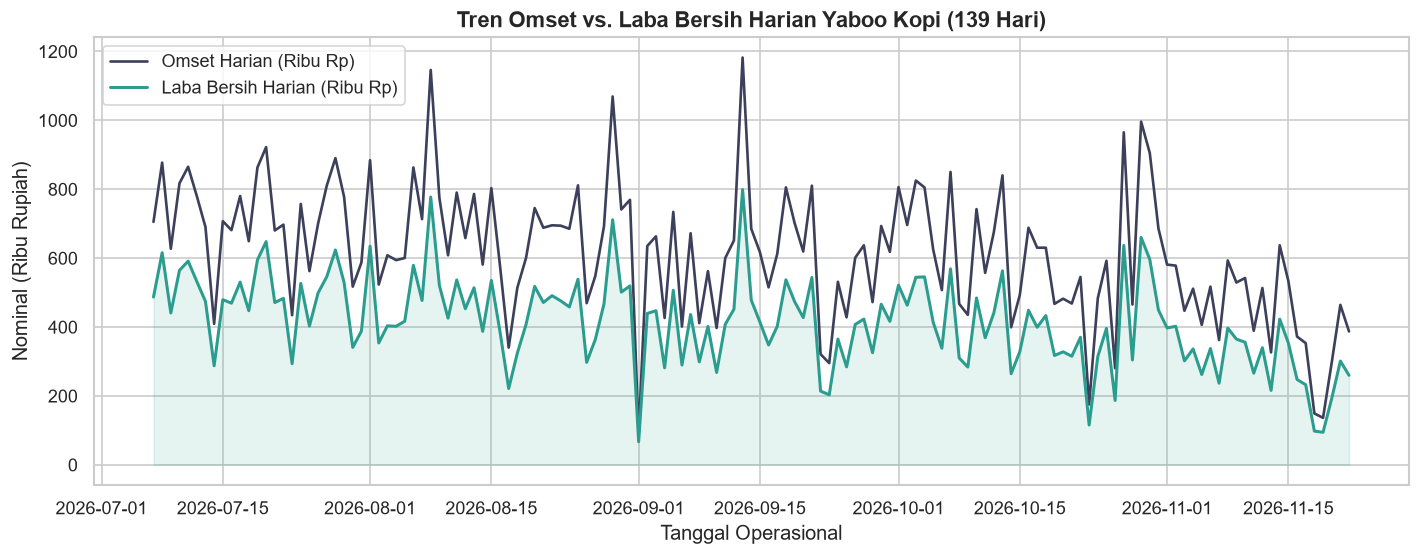

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(df_trend["tanggal"], df_trend["omset_idr"] / 1000, color="#3D405B", linewidth=1.6, label="Omset Harian (Ribu Rp)")
ax.plot(df_trend["tanggal"], df_trend["laba_bersih_idr"] / 1000, color="#2A9D8F", linewidth=1.8, label="Laba Bersih Harian (Ribu Rp)")
ax.fill_between(df_trend["tanggal"], df_trend["laba_bersih_idr"] / 1000, color="#2A9D8F", alpha=0.12)
ax.set_title("Tren Omset vs. Laba Bersih Harian Yaboo Kopi (139 Hari)", fontsize=13, fontweight="bold")
ax.set_xlabel("Tanggal Operasional")
ax.set_ylabel("Nominal (Ribu Rupiah)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("eda_charts_real/03_tren_omset_laba_harian.png")
plt.show()